# Experiment 3 — Deconfliction layers between two UAVs

This experiment compares strategic-only and tactical-only deconfliction for the same two-UAV encounter. UAV A and UAV B follow perpendicular routes and would otherwise reach the intersection simultaneously.

In [1]:
from pathlib import Path

from IPython.display import Image, display

from musas.airspace import Airspace
from musas.algorithms import (
    FirstOrderDynamics,
    FlightPlanAwareTracking,
    HybridGeometricManeuver,
    MinimumSeparationConflictPrediction,
    MinimumSeparationTacticalConflictPrediction,
    RecursiveTimeShiftDeconfliction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    calculate_metrics,
    plot_dataset,
)

OUTPUT_DIRECTORY = Path("outputs") / "output_exp3"
DATASET_DIRECTORY = OUTPUT_DIRECTORY / "datasets"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_DIRECTORY.mkdir(exist_ok=True)

## Scenario configuration

Both UAVs fly at the same altitude and would reach the origin at `t = 17 s`. UAV A is submitted first and has the higher priority, so both layers should preserve UAV A and modify UAV B.

In [2]:
SIMULATION_END = 50.0
ORIGINAL_ENCOUNTER_TIME = 17.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 5.0
TIME_SHIFT_STEP = 5.0
NETWORK_DELAY = 0.1


def create_flight_plans():
    return {
        "UAV A": FlightPlan(
            waypoint_list=[
                Waypoint(-100.0, 0.0, 100.0, 2.0),
                Waypoint(100.0, 0.0, 100.0, 32.0),
            ],
            priority=1,
        ),
        "UAV B": FlightPlan(
            waypoint_list=[
                Waypoint(0.0, -100.0, 100.0, 2.0),
                Waypoint(0.0, 100.0, 100.0, 32.0),
            ],
            priority=0,
        ),
    }

## Run the strategic-only and tactical-only cases

The SD case applies recursive time shift before departure. The TD case approves both original plans and uses predicted tracks to trigger a maneuver during execution.

In [3]:
CASES = {
    "sd_only": "With only strategic deconfliction",
    "td_only": "With only tactical deconfliction",
}


def run_case(case_name):
    dataset_path = DATASET_DIRECTORY / f"{case_name}.sqlite"
    strategic_predictor = None
    strategic_deconfliction = None
    tactical_predictor = None
    tactical_deconfliction = None
    tracking = None

    if case_name == "sd_only":
        strategic_predictor = MinimumSeparationConflictPrediction(
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            sampling_interval=0.25,
        )
        strategic_deconfliction = RecursiveTimeShiftDeconfliction(
            conflict_prediction_algorithm=strategic_predictor,
            time_shift_step=TIME_SHIFT_STEP,
            maximum_time_shifts=10,
        )

    elif case_name == "td_only":
        tactical_predictor = MinimumSeparationTacticalConflictPrediction(
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            maximum_time_difference=0.25,
        )
        tactical_deconfliction = HybridGeometricManeuver(
            conflict_prediction_algorithm=tactical_predictor,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            vertical_offset=60.0,
            maneuver_duration=4.0,
            recovery_duration=20.0,
            maximum_speed=15.0,
            cooldown=20.0,
        )
        tracking = FlightPlanAwareTracking()

    simulation = Simulation(
        airspace=Airspace(),
        network_delay=NETWORK_DELAY,
        flight_update_interval=0.1,
        trajectory_record_interval=0.1,
        dataset_path=dataset_path,
        dataset_metadata={
            "experiment": "deconfliction_between_uavs",
            "case": case_name,
        },
        overwrite_dataset=True,
        strategic_conflict_prediction_algorithm=strategic_predictor,
        strategic_deconfliction_algorithm=strategic_deconfliction,
        tracking_algorithm=tracking,
        tactical_conflict_prediction_algorithm=tactical_predictor,
        tactical_deconfliction_algorithm=tactical_deconfliction,
        report_interval=0.5,
        history_window=6,
        prediction_horizon=14,
        prediction_step=0.5,
        tactical_assessment_interval=0.1,
        collision_distance=COLLISION_DISTANCE,
    )

    for uav_name, flight_plan in create_flight_plans().items():
        simulation.add_uav(
            name=uav_name,
            flight_plan=flight_plan,
            dynamics_algorithm=FirstOrderDynamics(
                max_acceleration=100.0,
                velocity_time_constant=0.0,
            ),
            guidance_algorithm=WaypointGuidance(
                min_speed=0.0,
                max_speed=15.0,
            ),
            submission_time=0.0 if uav_name == "UAV A" else 0.5,
            waypoint_acceptance_radius=0.5,
        )

    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path


dataset_paths = {
    case_name: run_case(case_name)
    for case_name in CASES
}
dataset_paths

{'sd_only': PosixPath('outputs/output_exp3/datasets/sd_only.sqlite'),
 'td_only': PosixPath('outputs/output_exp3/datasets/td_only.sqlite')}

## Metrics

The comparison reports detections and interventions from each layer together with physical separation and collision outcomes.

In [4]:
print(
    f"{'Case':<38} {'SD conflicts':>12} {'TD detections':>14} "
    f"{'TD actions':>11} {'modified':>10} {'LOS':>6} "
    f"{'collisions':>11} {'minimum sep.':>14}"
)
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            collision_distance=COLLISION_DISTANCE,
        )
    minimum_separation = metrics["minimum_pairwise_separation"]
    minimum_separation_text = (
        "n/a"
        if minimum_separation is None
        else f"{minimum_separation:.2f}"
    )
    print(
        f"{CASES[case_name]:<38} "
        f"{metrics['detected_strategic_conflicts']:12d} "
        f"{metrics['detected_tactical_conflicts']:14d} "
        f"{metrics['tactical_interventions']:11d} "
        f"{metrics['modified_flights']:10d} "
        f"{metrics['loss_of_separation_events']:6d} "
        f"{metrics['collision_events']:11d} "
        f"{minimum_separation_text:>14}"
    )

Case                                   SD conflicts  TD detections  TD actions   modified    LOS  collisions   minimum sep.
With only strategic deconfliction                 1              0           0          1      0           0          47.46
With only tactical deconfliction                  0              5           1          1      0           0          57.51


## Authorized flight plans

The latest authorized version shows whether each layer changed timing, geometry, or both.

In [5]:
for case_name, dataset_path in dataset_paths.items():
    print(f"\n{CASES[case_name]}:")
    with SimulationDataset(dataset_path) as dataset:
        for uav_name in ("UAV A", "UAV B"):
            versions = dataset.get_flight_plan_versions(uav_name)
            plan = dataset.get_flight_plan(
                uav_name, "authorized", versions[-1]
            )
            print(f"  {uav_name} — version {versions[-1]}:")
            for waypoint in plan.waypoint_list:
                print(
                    f"    ({waypoint.x:7.2f}, {waypoint.y:7.2f}, "
                    f"{waypoint.z:6.2f}) at t={waypoint.t:6.2f} s"
                )


With only strategic deconfliction:
  UAV A — version 0:
    (-100.00,    0.00, 100.00) at t=  2.00 s
    ( 100.00,    0.00, 100.00) at t= 32.00 s
  UAV B — version 0:
    (   0.00, -100.00, 100.00) at t= 12.00 s
    (   0.00,  100.00, 100.00) at t= 42.00 s

With only tactical deconfliction:
  UAV A — version 0:
    (-100.00,    0.00, 100.00) at t=  2.00 s
    ( 100.00,    0.00, 100.00) at t= 32.00 s
  UAV B — version 1:
    (   0.00,  -65.33, 100.00) at t=  7.10 s
    (   0.00,  -48.67,  40.00) at t= 11.25 s
    (   0.00,   11.33,  40.00) at t= 15.25 s
    (   0.00,  100.00, 100.00) at t= 35.25 s


## Flight-plan, trajectory, and track figures

The XZ side view makes the tactical vertical maneuver directly visible. Track predictions are displayed when available.

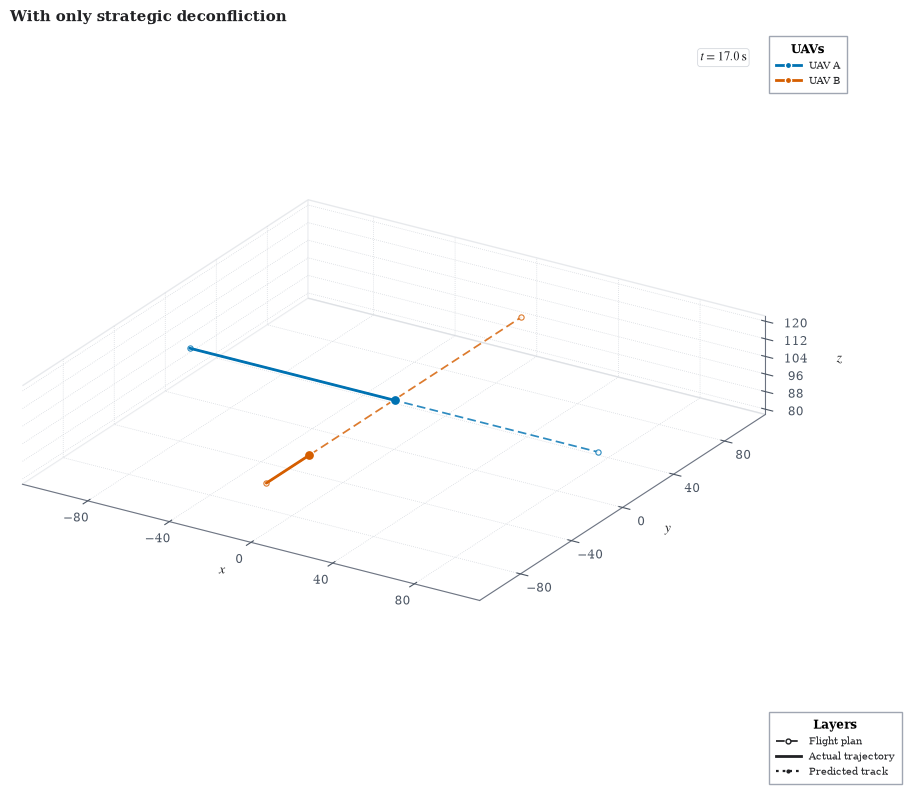

Saved: outputs/output_exp3/sd_only.png


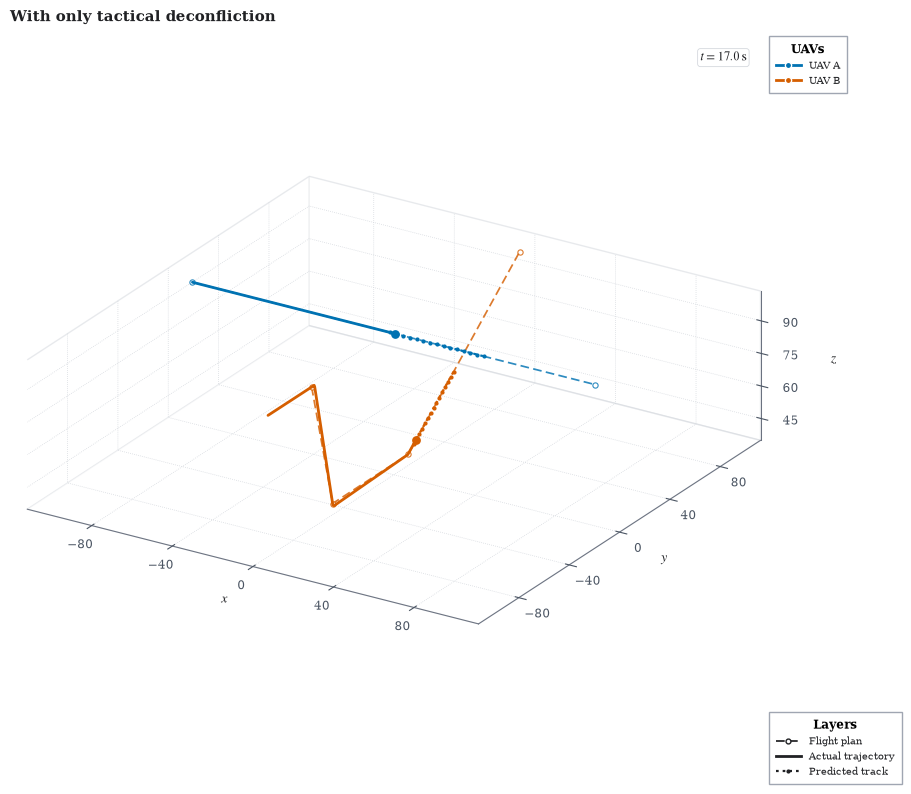

Saved: outputs/output_exp3/td_only.png


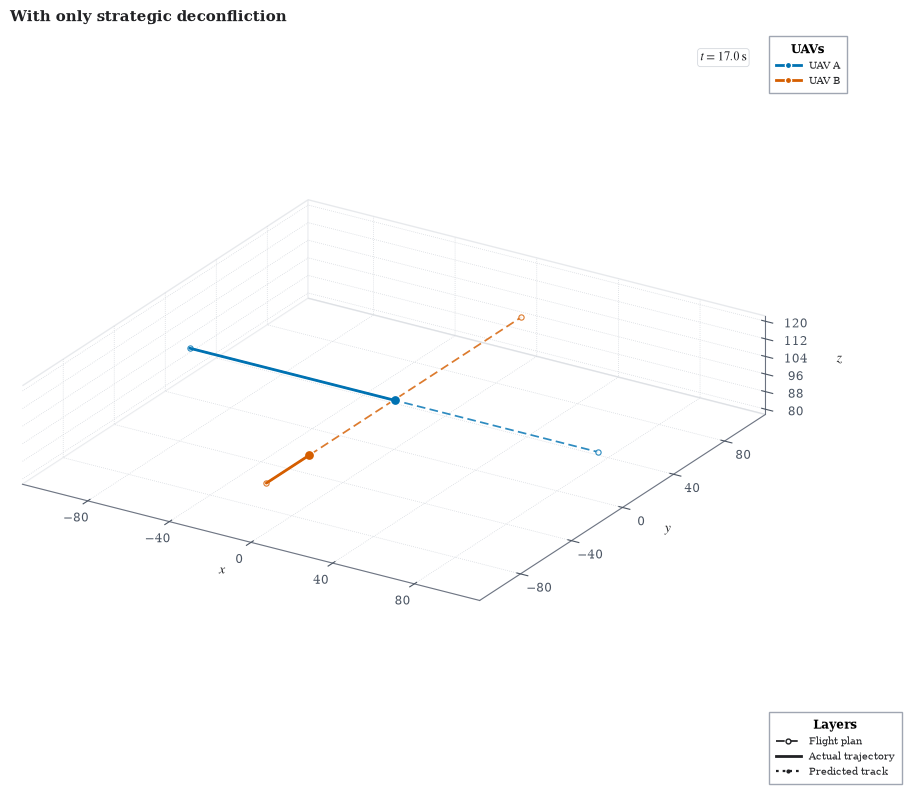

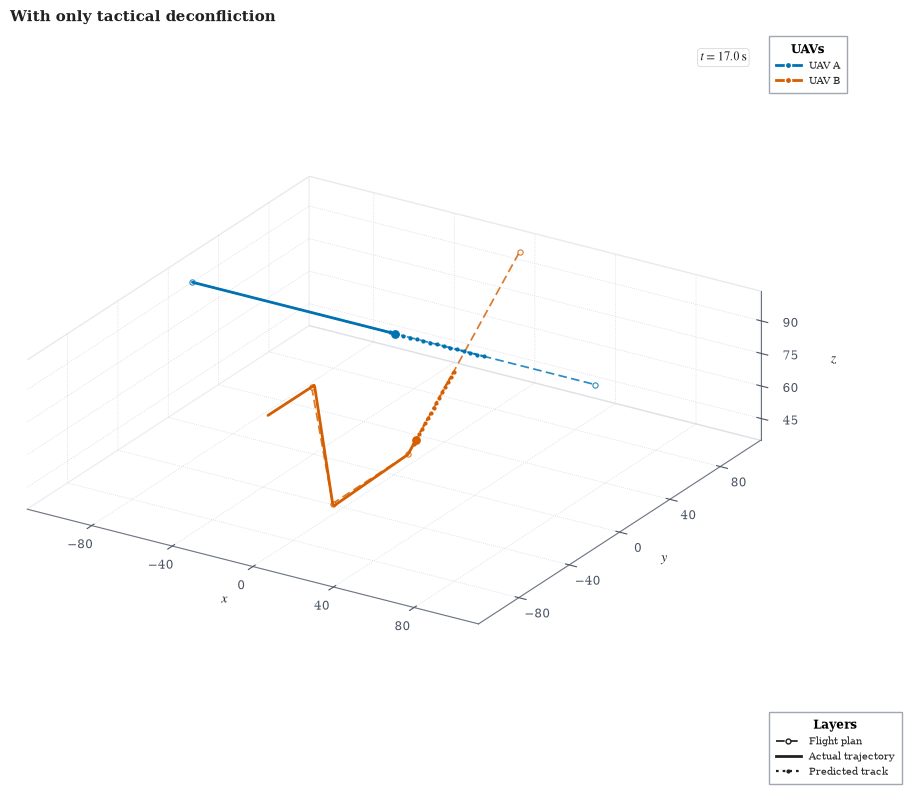

In [6]:
def visualization_config(case_name):
    return VisualizationConfig(
        uav_names=("UAV A", "UAV B"),
        view="3d" if case_name == "td_only" else "3d",
        show_real_trajectories=True,
        show_current_positions=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_tracks=True,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=False,
        frame_step=0.5,
        figure_size=(9.0, 8.0),
        title=CASES[case_name],
    )


for case_name, dataset_path in dataset_paths.items():
    figure_path = OUTPUT_DIRECTORY / f"{case_name}.png"
    figure = plot_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name),
        timestamp=ORIGINAL_ENCOUNTER_TIME,
        output_path=figure_path,
    )
    display(figure)
    print("Saved:", figure_path)

## Animations

The tactical animation includes the predicted tracks as they evolve.

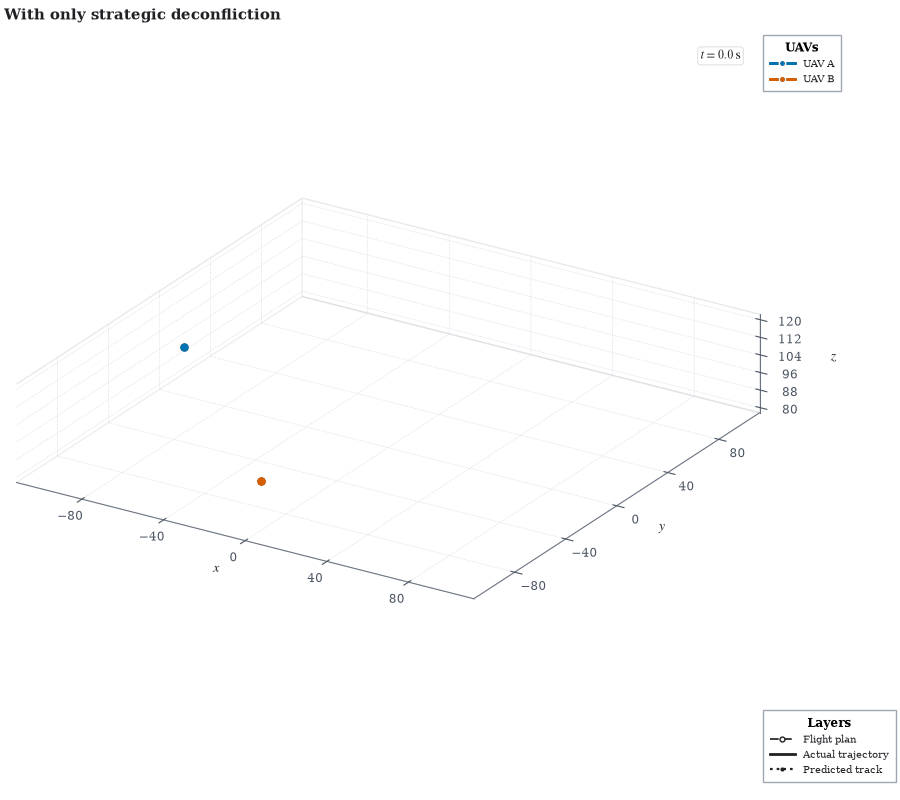

Saved: outputs/output_exp3/sd_only.gif


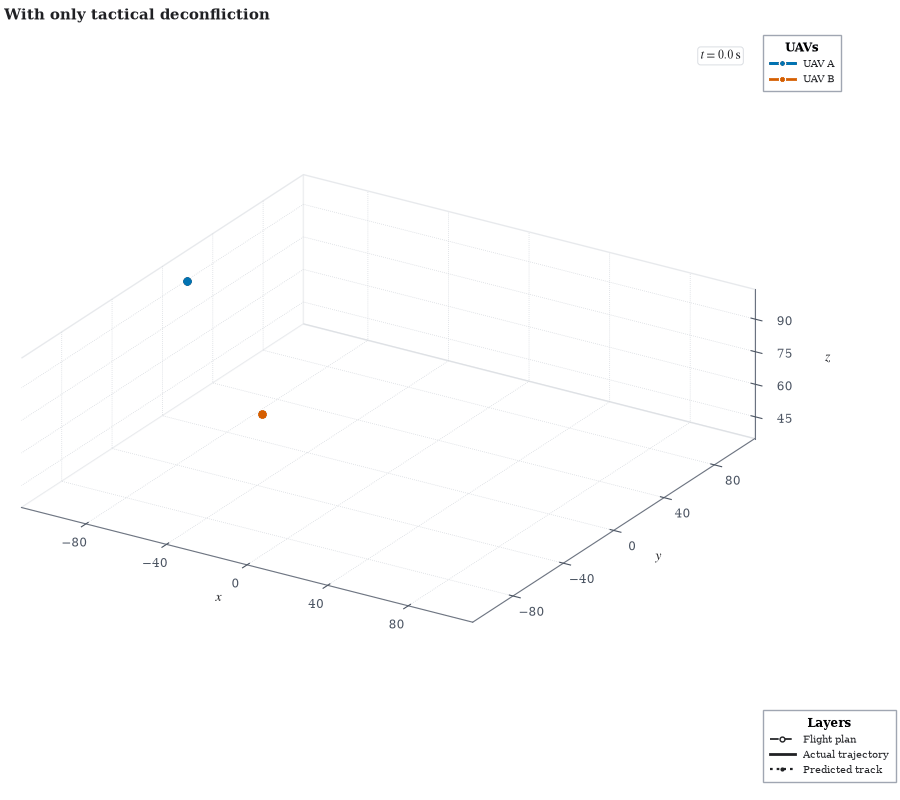

Saved: outputs/output_exp3/td_only.gif


In [7]:
for case_name, dataset_path in dataset_paths.items():
    animation_path = OUTPUT_DIRECTORY / f"{case_name}.gif"
    animate_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name),
        output_path=animation_path,
        fps=6.0,
        dpi=100,
    )
    display(Image(filename=animation_path))
    print("Saved:", animation_path)

## Expected interpretation

With strategic deconfliction, UAV B should be delayed before departure according to FCFS. With tactical deconfliction, both original plans are initially approved and UAV B should receive an in-flight update after the tracks reveal the encounter. In both cases, UAV A should retain its original operation.